# ДЗ 2. Прогнозирование продаж

## 1. Данные и разбиение по времени
### Календарь продаж

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd

root = Path.cwd()
if root.name == "hw2":
    root = root.parent
sys.path.insert(0, str(root))
from hw1 import ts_tools as prep
from hw2 import ts_tools as forecast

pd.set_option("display.precision", 2)
product_code = "84692"
horizons = {"День": (1, 7, 31, 61), "Неделя": (1, 4, 8), "Месяц": (1, 2)}
n_origins = {"День": 24, "Неделя": 8, "Месяц": 4}

In [2]:
daily = prep.make_daily(prep.load_transactions(root / "Online Retail.xlsx"), product_code)
weekly = prep.aggregate(daily, "W")
monthly = prep.aggregate(daily, "M")
monthly.index = monthly.index + pd.offsets.MonthEnd(0)
sales = {"День": daily, "Неделя": weekly, "Месяц": monthly}

calendar = pd.date_range(daily.index.min(), daily.index.max())
expected = {
    "День": calendar[calendar.dayofweek != 5],
    "Неделя": pd.date_range(weekly.index.min(), weekly.index.max(), freq="W-SUN"),
    "Месяц": pd.date_range(monthly.index.min(), monthly.index.max(), freq="ME"),
}
for frequency, values in sales.items():
    assert values.index.equals(expected[frequency]) and values.index.is_unique and values.index.is_monotonic_increasing

pd.DataFrame([{"частота": frequency, "с": values.index.min().date(), "по": values.index.max().date(),
               "позиций": len(values), "пропусков": values.isna().sum(), "нулей": values.eq(0).sum(),
               "продано, шт.": int(values.sum())} for frequency, values in sales.items()])

,частота,с,по,позиций,пропусков,нулей,"продано, шт."
0,День,2010-12-01,2011-12-09,321,16,46,7908
1,Неделя,2010-12-12,2011-12-04,52,1,0,7548
2,Месяц,2010-12-31,2011-11-30,12,0,0,7689


В дневном ряду 321 дата. В 46 из них у магазина были транзакции, но никто не купил этот товар. Это нулевые продажи. Ещё за 16 дат нет записей по всему магазину. Их оставляем пропущенными. Суббот в выгрузке нет, поэтому одна неделя соответствует шести дневным шагам.

Как и в ДЗ 1, исключаем возвраты, отмены и строки с нулевой ценой. По неделям и месяцам суммируем известные продажи только за полные календарные периоды. Поэтому итоги для трёх частот различаются. Одна из 52 недель целиком пропущена.

### Обучающие и тестовые окна
Используем расширяющееся окно со слайда 26 лекции. При каждом сдвиге к обучающему ряду добавляется один завершившийся период. От последней границы обучения до конца ряда оставляем столько позиций, сколько требует самый длинный прогноз.

In [3]:
windows = {}
splits = []
for frequency, values in sales.items():
    steps = horizons[frequency]
    sizes = forecast.training_sizes(len(values), max(steps), n_origins[frequency])
    windows[frequency] = sizes
    first, last = sizes[0], sizes[-1]
    splits.append({
        "частота": frequency, "горизонты": ", ".join(map(str, steps)),
        "окон": len(sizes), "длина обучения": f"{first}–{last}",
        "первая граница": values.index[first - 1].date(),
        "последняя граница": values.index[last - 1].date(),
        "первая дата теста": values.index[first].date(), "конец теста": values.index[-1].date(),
    })
pd.DataFrame(splits).set_index("частота")

,горизонты,окон,длина обучения,первая граница,последняя граница,первая дата теста,конец теста
частота,,,,,,,
День,"1, 7, 31, 61",24,237–260,2011-09-02,2011-09-29,2011-09-04,2011-12-09
Неделя,"1, 4, 8",8,37–44,2011-08-21,2011-10-09,2011-08-28,2011-12-04
Месяц,"1, 2",4,7–10,2011-06-30,2011-09-30,2011-07-31,2011-11-30


Дневной прогноз проверяем с 24 стартовых дат, недельный с 8, месячный с 4. Для месячной модели в первом окне доступны семь завершившихся месяцев, в последнем — десять. Дата месячного наблюдения соответствует концу месяца, когда уже известны его продажи.

В обучающей части дневной пропуск заполняем средним по тому же дню недели за прошлые даты. Если такого дня ещё не было, берём последнее известное значение. Так же заполняем пропущенную неделю. Для оценки используем только исходные наблюдения.

## 2. Модели и прогнозы

- **Наивная модель** для дневного ряда повторяет последние шесть значений, сохраняя различия между днями недели. Для недель и месяцев она повторяет продажи за последний период.
- **Простое экспоненциальное сглаживание (SES)** даёт один прогноз уровня продаж на все шаги вперёд. Начальный уровень и коэффициент сглаживания модель оценивает заново в каждом окне.
- **CatBoost** на каждом шаге использует лаги и среднее за предыдущие периоды. Для дней берём лаги 1, 6 и 12 и день недели, для недель — лаги 1, 2 и 4, для месяцев — 1 и 2. Длина окна для среднего равна наибольшему лагу. Как в семинаре, для второго и следующих шагов подставляем в историю собственные прогнозы. При обучении пропускаем примеры с неизвестными целевыми продажами. Во всех окнах используем 120 деревьев глубины 2 и скорость обучения 0,05.

Наивный прогноз и SES разобраны на слайдах 3–6, рекурсивный бустинг и его признаки — на слайдах 23–24. Реализации есть в [ts_tools.py](ts_tools.py).

In [4]:
forecasts = pd.concat([
    forecast.backtest(values, frequency, windows[frequency], max(horizons[frequency]))
    for frequency, values in sales.items()
], ignore_index=True)
assert (forecasts["дата"] > forecasts["конец обучения"]).all()
assert np.isfinite(forecasts["прогноз"]).all()
assert not forecasts.duplicated(["частота", "модель", "конец обучения", "шаг"]).any()
forecasts.to_csv(root / "hw2" / "forecasts.csv", index=False)

daily_first = forecasts[(forecasts["частота"] == "День") & (forecasts["шаг"] == 1)]
daily_first.loc[daily_first["дата"] == daily_first["дата"].min(),
                ["конец обучения", "дата", "модель", "прогноз", "факт"]]

,конец обучения,дата,модель,прогноз,факт
0,2011-09-02,2011-09-04,Наивная,0.00,3.0
61,2011-09-02,2011-09-04,SES,19.07,3.0
122,2011-09-02,2011-09-04,CatBoost,10.72,3.0


На воскресенье 4 сентября наивная модель предсказала 0 наборов, CatBoost около 11, SES около 19. Купили 3 набора. В этот день ближе к факту оказалась наивная модель. Для выбора модели на один день вперёд сравним ошибки по всем 24 окнам.

## 3. Метрики и сравнение по горизонтам
Основная метрика MAE показывает, на сколько наборов в среднем прогноз расходится с фактом. RMSE тоже измеряется в наборах, но сильнее учитывает крупные промахи. Для сравнения частот берём WAPE в процентах. Для этого делим сумму абсолютных ошибок на сумму фактических продаж. Дни с нулевыми продажами входят в расчёт.

На горизонте `h` берём ошибку ровно на шаге `h` от каждой границы обучения. Например, на горизонте 7 в дневном ряду сравниваем седьмой прогноз каждого окна с продажами за соответствующий день.

In [5]:
scores = forecast.score_forecasts(forecasts, horizons)
for frequency, steps in horizons.items():
    block = scores[scores["частота"] == frequency]
    assert set(block["шаг"]) == set(steps)
    assert block.groupby("шаг")["модель"].nunique().eq(3).all()
    assert block["наблюдений"].eq(n_origins[frequency]).all()
assert len(scores) == 27 and np.isfinite(scores[["MAE", "RMSE", "WAPE, %"]]).all().all()
scores.to_csv(root / "hw2" / "metrics.csv", index=False)
scores.set_index(["частота", "шаг", "модель"]).round(2)

наблюдений     MAE    RMSE  WAPE, %
частота шаг модель                                       
День    1   CatBoost          24   19.15   26.18    64.46
            SES               24   19.64   26.37    66.10
            Наивная           24   24.03   31.05    80.88
        7   CatBoost          24   23.01   29.07    79.46
            SES               24   22.96   28.77    79.30
            Наивная           24   27.47   39.42    94.87
        31  CatBoost          24   25.96   37.30    94.12
            SES               24   25.72   37.08    93.25
            Наивная           24   21.76   34.40    78.90
        61  CatBoost          24   17.10   22.90    75.05
            SES               24   18.57   23.77    81.46
            Наивная           24   23.89   32.74   104.81
Неделя  1   CatBoost           8   51.28   69.00    35.03
            SES                8   73.21   90.83    50.02
            Наивная            8  126.62  138.41    86.51
        4   CatBoost           8   64.60   89.55    37.92
            SES                8   63.98   86.88    37.55
            Наивная            8  106.62  143.46    62.58
        8   CatBoost           8   59.47   68.54    36.60
            SES                8   44.43   55.78    27.34
            Наивная            8   62.25   73.07    38.31
Месяц   1   CatBoost           4  156.79  184.52    26.14
            SES                4  121.88  157.39    20.32
            Наивная            4  147.00  167.84    24.51
        2   CatBoost           4  188.86  200.04    29.38
            SES                4  131.75  133.62    20.50
            Наивная            4  107.00  114.16    16.65

На один день вперёд у CatBoost наименьшая MAE, 19,15 набора против 24,03 у наивной модели. По RMSE он тоже первый (26,18). На семь дней разница между SES и CatBoost по MAE составляет всего 0,05 набора. Такой разрыв на одной выборке сам по себе не даёт оснований ожидать преимущества SES в будущем.

## 4. Графики факта и прогноза
На каждом графике вертикальная линия отмечает последнюю границу обучения. Справа от неё показаны прогнозы, которые модели сделали в этот момент.

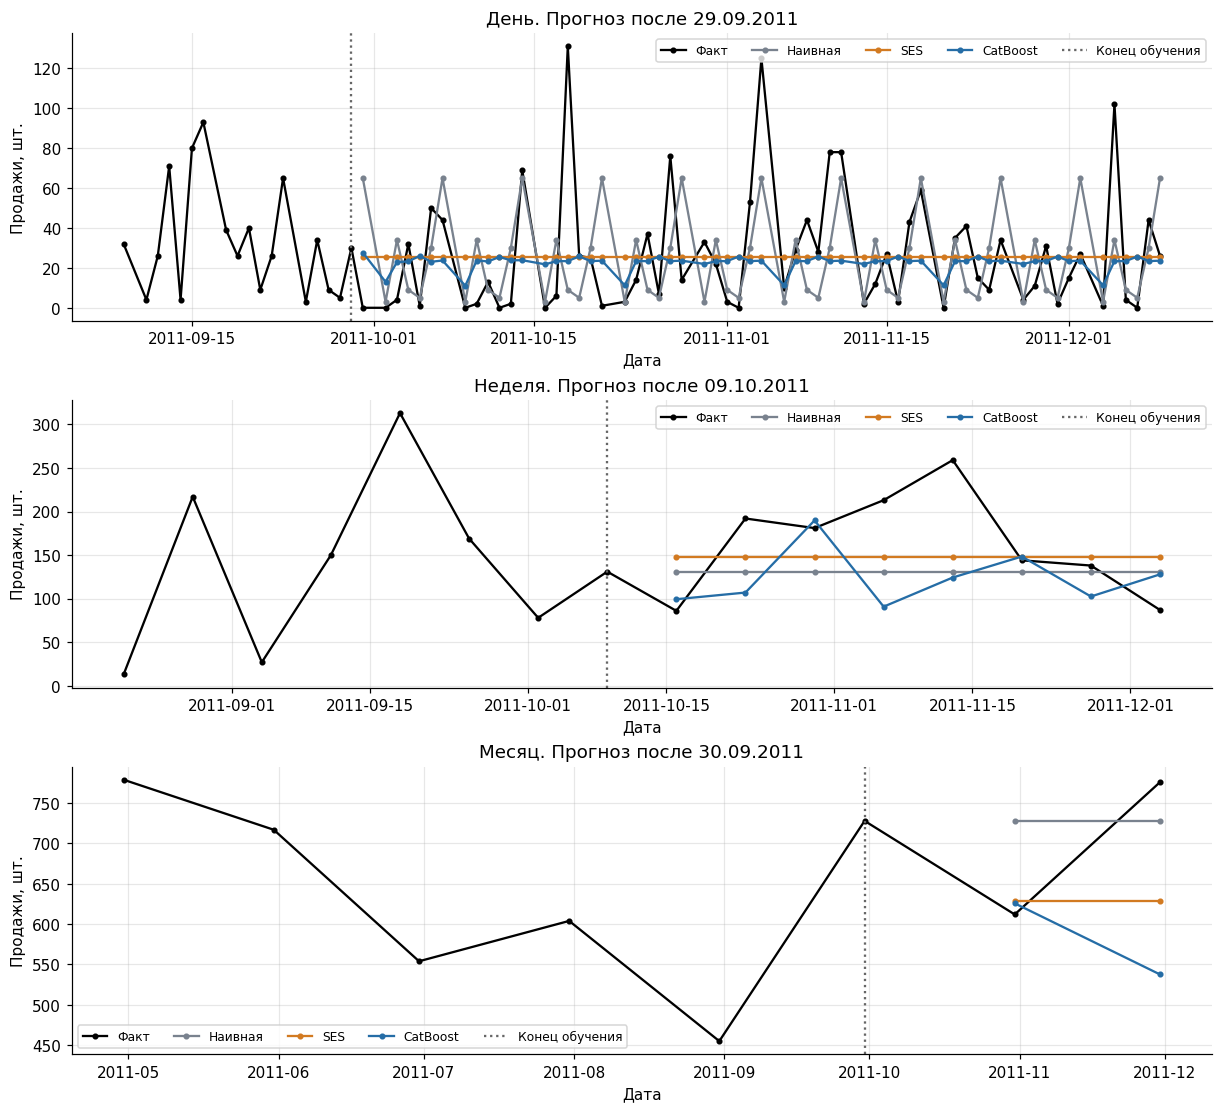

In [6]:
forecast.plot_forecasts(sales, forecasts)

В дневном ряду наивная модель повторяет пики последней недели. У SES прогноз остаётся постоянным. Например, после сентября SES предсказала около 628 наборов и на октябрь, и на ноябрь. В октябре купили 612 наборов, в ноябре уже 776. Модель попала близко к октябрьским продажам и пропустила ноябрьский рост.

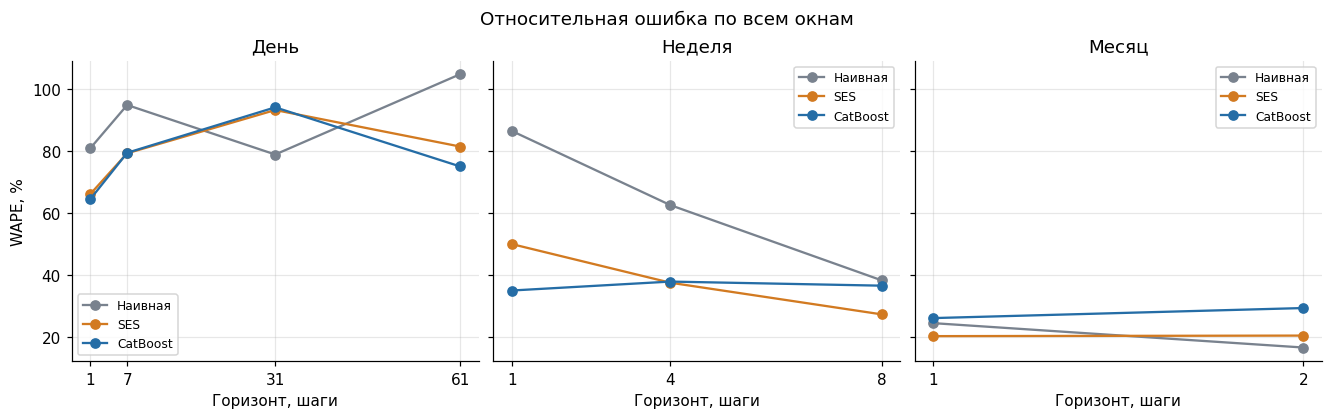

In [7]:
forecast.plot_relative_errors(scores, horizons)

На 61-м дневном шаге WAPE наивной модели равна 104,81%. Суммарная абсолютная ошибка превысила объём продаж на проверенных датах. У недельной SES при переходе с четырёх шагов на восемь WAPE снизилась с 37,55% до 27,34%. На каждом шаге проверяются другие даты, поэтому по этому снижению нельзя заключить, что прогноз на восемь недель обычно точнее.

## 5. Выводы
Для каждой частоты и горизонта выберем модель с наименьшей MAE.

In [8]:
best = scores.loc[scores.groupby(["частота", "шаг"])["MAE"].idxmin()]
order = [(frequency, step) for frequency, steps in horizons.items() for step in steps]
best.set_index(["частота", "шаг"]).loc[order].round(2)

модель  наблюдений     MAE    RMSE  WAPE, %
частота шаг                                               
День    1    CatBoost          24   19.15   26.18    64.46
        7         SES          24   22.96   28.77    79.30
        31    Наивная          24   21.76   34.40    78.90
        61   CatBoost          24   17.10   22.90    75.05
Неделя  1    CatBoost           8   51.28   69.00    35.03
        4         SES           8   63.98   86.88    37.55
        8         SES           8   44.43   55.78    27.34
Месяц   1         SES           4  121.88  157.39    20.32
        2     Наивная           4  107.00  114.16    16.65

**Дни.** CatBoost дал наименьшую MAE на первом и 61-м шагах (19,15 и 17,10 набора), SES на 7-м, сезонная наивная модель на 31-м (21,76). Одной модели, которая точнее остальных на всех дневных горизонтах, здесь нет. Крупные разовые заказы могут объяснять часть ошибок. Модели учитывают прошлые продажи, а сведений о предстоящих заказах у них нет.

**Недели.** На одну неделю вперёд точнее CatBoost (MAE 51,28 набора). На четырёх неделях у SES и CatBoost близкие ошибки (63,98 и 64,60). На восьми преимущество SES заметнее (44,43 против 59,47). Простое повторение объёма последней недели дало наибольшую MAE на всех трёх горизонтах.

**Месяцы.** На один месяц вперёд наименьшая MAE у SES (121,88 набора), на два — у наивной модели (107,00). Для обучения CatBoost после формирования лагов остаётся всего 5–8 примеров. Каждый месячный результат основан на четырёх прогнозах. Этого мало, чтобы уверенно выбрать модель для следующего года или оценить годовую сезонность.

**Горизонт и частота.** Ошибка не всегда растёт с горизонтом. У недельной SES значения MAE на шагах 1, 4 и 8 составили 73,21, 63,98 и 44,43 набора. У лучших по MAE моделей WAPE по дневным горизонтам составила около 64–79%, по недельным 27–38%, по месячным 17–20%. Это результаты одного товара за конкретные периоды. Даты проверки зависят от горизонта, а соседние окна перекрываются.